# Exercice 1

In [1]:
import numpy as np
np.set_printoptions(threshold=10000, suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("credit_scoring.csv", sep=";")

In [3]:
print(df.head())

   Seniority  Home  Time   Age  Marital  Records  Job  Expenses  Income  \
0        9.0   1.0  60.0  30.0      0.0      1.0  1.0      73.0   129.0   
1       17.0   1.0  60.0  58.0      1.0      1.0  0.0      48.0   131.0   
2       10.0   0.0  36.0  46.0      0.0      2.0  1.0      90.0   200.0   
3        0.0   1.0  60.0  24.0      1.0      1.0  0.0      63.0   182.0   
4        0.0   1.0  36.0  26.0      1.0      1.0  0.0      46.0   107.0   

   Assets  Debt  Amount   Price  Status  
0     0.0   0.0   800.0   846.0       1  
1     0.0   0.0  1000.0  1658.0       1  
2  3000.0   0.0  2000.0  2985.0       0  
3  2500.0   0.0   900.0  1325.0       1  
4     0.0   0.0   310.0   910.0       1  


In [4]:
array = df.values

In [5]:
print(df.columns.tolist())

['Seniority', 'Home', 'Time', 'Age', 'Marital', 'Records', 'Job', 'Expenses', 'Income', 'Assets', 'Debt', 'Amount', 'Price', 'Status']


In [6]:
print(df.columns)

Index(['Seniority', 'Home', 'Time', 'Age', 'Marital', 'Records', 'Job',
       'Expenses', 'Income', 'Assets', 'Debt', 'Amount', 'Price', 'Status'],
      dtype='object')


### On separe les variables caracteristiques (on prend toutes les colonnes sauf Status)

In [7]:
X = df.drop(columns=["Status"])

In [8]:
print(X)

      Seniority  Home  Time   Age  Marital  Records  Job  Expenses  Income  \
0           9.0   1.0  60.0  30.0      0.0      1.0  1.0      73.0   129.0   
1          17.0   1.0  60.0  58.0      1.0      1.0  0.0      48.0   131.0   
2          10.0   0.0  36.0  46.0      0.0      2.0  1.0      90.0   200.0   
3           0.0   1.0  60.0  24.0      1.0      1.0  0.0      63.0   182.0   
4           0.0   1.0  36.0  26.0      1.0      1.0  0.0      46.0   107.0   
...         ...   ...   ...   ...      ...      ...  ...       ...     ...   
4370        1.0   1.0  60.0  39.0      0.0      1.0  0.0      69.0    92.0   
4371       22.0   0.0  60.0  46.0      0.0      1.0  0.0      60.0    75.0   
4372        0.0   0.0  24.0  37.0      0.0      1.0  1.0      60.0    90.0   
4373        0.0   1.0  48.0  23.0      1.0      1.0  1.0      49.0   140.0   
4374        5.0   0.0  60.0  32.0      0.0      1.0  1.0      60.0   140.0   

      Assets    Debt  Amount   Price  
0        0.0     0.0   8

### Variable à prédire

In [9]:
Y = df["Status"]

In [10]:
print(Y)

0       1
1       1
2       0
3       1
4       1
       ..
4370    0
4371    1
4372    0
4373    1
4374    1
Name: Status, Length: 4375, dtype: int64


### Utilisation de Shape pour voir la taille de l'echantillon,
### ici on a 4375 pour 13 lignes en ce qui concerne les variables caractéristiques

In [11]:
print(X.shape)

(4375, 13)


### Pourcentage des Oui et des Non 
### Normalize=True utilisé pour avoir les proportions (fréquences) 

In [12]:
pourcentage = df["Status"].value_counts(normalize=True).round(2) * 100
print(pourcentage)

Status
1    72.0
0    28.0
Name: proportion, dtype: float64


In [13]:
X_train, X_test, y_train, y_test = train_test_split (
    X, Y,
    test_size=0.5,
    random_state=1
)

In [14]:
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (2187, 13)
X_test  : (2188, 13)
y_train : (2187,)
y_test  : (2188,)


In [15]:
print("Proportions dans le train :")
print(pd.Series(y_train).value_counts(normalize=True) * 100)

print("\nProportions dans le test :")
print(pd.Series(y_test).value_counts(normalize=True) * 100)

Proportions dans le train :
Status
1    72.016461
0    27.983539
Name: proportion, dtype: float64

Proportions dans le test :
Status
1    72.394881
0    27.605119
Name: proportion, dtype: float64


# Exercice 2

# Notions:
    -Accuracy: pourcentage total de prédictions correctes parmi toutes les prédictions.

    -Précision: indique parmi toutes les prédictions positives du modèle, quelle part était réellement positive (à privileger si on veut minimiser les faux-positifs).

    -Rappel(oui): indique parmi toutes les valeurs positives réelles, quelle part a été correctement trouvée par le modèle (à privileger si on veut minimiser les faux négatifs)

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "CART": DecisionTreeClassifier(random_state=1),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "MLP": MLPClassifier(hidden_layer_sizes=(40,20), random_state=1, max_iter=500)
}

# Fonction d'évaluation du modèle



In [17]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, roc_curve, auc
import matplotlib.pyplot as plt

def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)

    meilleur_critere = prec
    score_final = (acc + meilleur_critere) / 2

    print(f"\n=== {name} ===")
    print("Matrice de confusion :")
    print(cm)
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"Score final : {score_final:.4f}")

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = auc(fpr, tpr)

    plt.figure(figsize=(6,5))
    plt.plot(fpr, tpr, label=f"AUC = {auc_val:.3f}")
    plt.plot([0,1], [0,1], "--", color="gray")
    plt.title(f"ROC - {name}")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.legend()
    plt.grid()
    plt.show()

    return score_final

#  Fonction d’apprentissage et de test

In [18]:
def run_classifiers_train_test(models, X_train, y_train, X_test, y_test):
    scores = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        score = evaluate_model(name, model, X_test, y_test)
        scores[name] = score

    best = max(scores, key=scores.get)

    print("\nMeilleur modèle :", best)
    print("Score final :", scores[best])

    return best, models[best]


=== CART ===
Matrice de confusion :
[[ 325  279]
 [ 318 1266]]
Accuracy  : 0.7271
Precision : 0.8194
Recall    : 0.7992
Score final : 0.7733


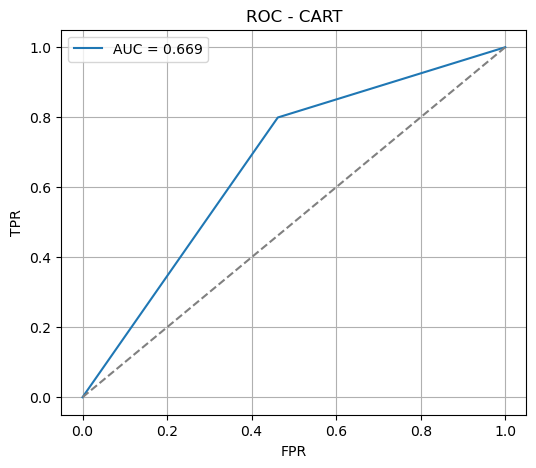


=== kNN ===
Matrice de confusion :
[[ 189  415]
 [ 187 1397]]
Accuracy  : 0.7249
Precision : 0.7710
Recall    : 0.8819
Score final : 0.7479


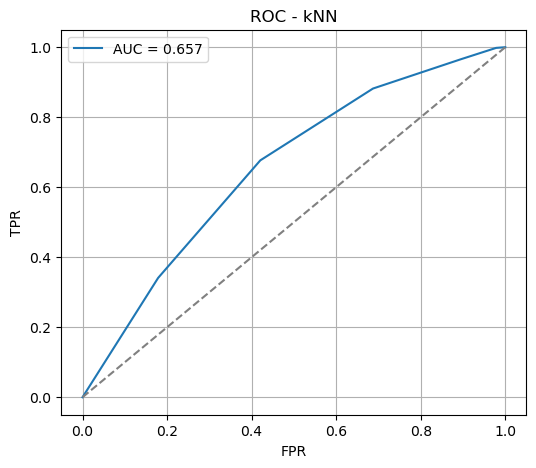


=== MLP ===
Matrice de confusion :
[[ 543   61]
 [1092  492]]
Accuracy  : 0.4730
Precision : 0.8897
Recall    : 0.3106
Score final : 0.6814


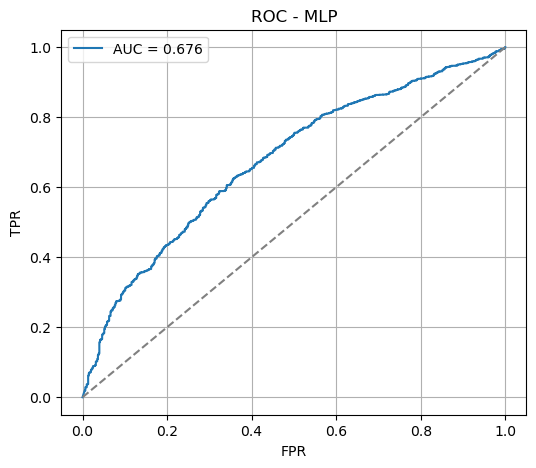


Meilleur modèle : CART
Score final : 0.7732827780834561


In [19]:
best_name, best_model = run_classifiers_train_test(
    models,
    X_train, y_train,
    X_test, y_test
)

# Interprétation des résultats et éxplications





Pour comparer les différents modèles de classification, nous avons évalué à la fois l’accuracy, la précision et le rappel. Dans le cas particulier du crédit scoring, l’enjeu principal pour la banque est d’éviter d’accorder un prêt à une personne qui ne remboursera pas, et donc minimiser au maximum les pertes d'argent. Cette erreur correspond à un faux positif, c’est-à-dire prédire que le client est fiable alors qu’il ne l’est pas, ce qui entraîne une perte financière directe. C’est pourquoi le critère le plus pertinent dans ce contexte est la précision, qui mesure la proportion de clients prédits comme fiables et qui le sont réellement. 

Le score final retenu correspond donc à la moyenne entre l’accuracy et la précision. Sur les données non normalisées, l’algorithme obtenant le meilleur score selon cette stratégie est l’arbre de décision CART (avec un score final de 0.77), qui se montre le plus efficace pour séparer correctement les bons et les mauvais payeurs dans ce premier scénario.

# Exercice 3

## Normalisation des données avec StandardScaler

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   
X_test_scaled = scaler.transform(X_test)

## Modification de la fonction d'apprentissage 
## (car on n'utilise pas les memes données)

In [21]:
def run_classifiers_train_test(models, 
                               X_train, 
                               X_train_scaled, 
                               y_train, 
                               X_test, X_test_scaled, 
                               y_test):

    scores = {}

    for name, model in models.items():

        # Choix des données selon le modèle
        if name in ["kNN", "MLP"]:
            Xtr, Xte = X_train_scaled, X_test_scaled
        else:
            Xtr, Xte = X_train, X_test

        model.fit(Xtr, y_train)
        score = evaluate_model(name, model, Xte, y_test)
        scores[name] = score

    best = max(scores, key=scores.get)
    print("\nMeilleur modèle après normalisation :", best)
    return best, models[best]


=== CART ===
Matrice de confusion :
[[ 325  279]
 [ 318 1266]]
Accuracy  : 0.7271
Precision : 0.8194
Recall    : 0.7992
Score final : 0.7733


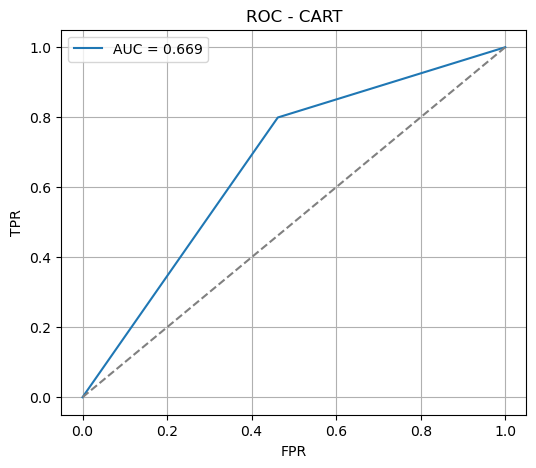


=== kNN ===
Matrice de confusion :
[[ 286  318]
 [ 223 1361]]
Accuracy  : 0.7527
Precision : 0.8106
Recall    : 0.8592
Score final : 0.7817


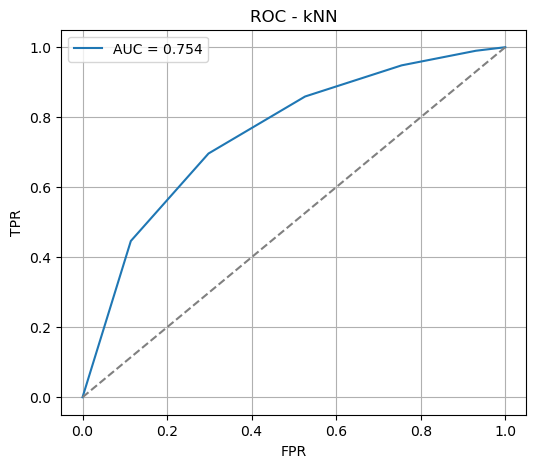


=== MLP ===
Matrice de confusion :
[[ 330  274]
 [ 254 1330]]
Accuracy  : 0.7587
Precision : 0.8292
Recall    : 0.8396
Score final : 0.7939


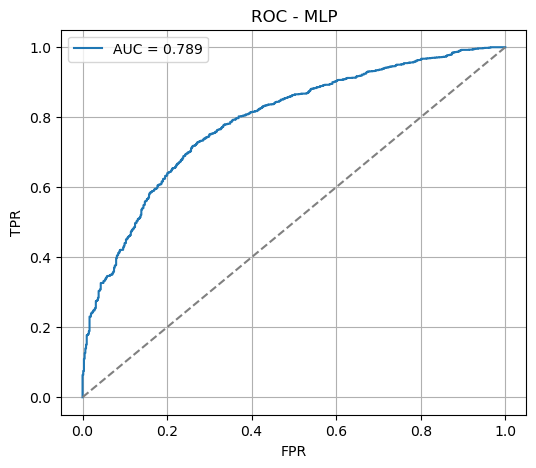


Meilleur modèle après normalisation : MLP


In [22]:
best_norm_name, best_norm_model = run_classifiers_train_test(
    models,
    X_train, X_train_scaled,
    y_train,
    X_test, X_test_scaled,
    y_test
)

## Résultats:

Après avoir appliqué une normalisation standard sur les variables continues, nous avons réexécuté la même procédure d’évaluation que précédemment. Les résultats montrent que la normalisation a un impact significatif sur certains algorithmes, notamment le k-plus-proches-voisins et le Multilayer Perceptron, qui sont sensibles à l’échelle des données.

 En particulier, le MLP voit ses performances fortement augmenter et devient le meilleur modèle après normalisation, avec une précision et un rappel nettement supérieurs et un score de 0.79. À l’inverse, l’arbre de décision CART, qui repose sur des règles de segmentation et non sur des distances, n’est pas affecté par la normalisation et conserve des résultats similaires à ceux obtenus précédemment.





# Exercice 4

##  Application de la PCA (ACP) et création de nouvelles variables

In [23]:
from sklearn.decomposition import PCA
import numpy as np

pca = PCA(n_components=3)

# fit uniquement sur train
X_train_pca = pca.fit_transform(X_train_scaled)

X_test_pca = pca.transform(X_test_scaled)

print("Forme des nouvelles variables PCA (train) :", X_train_pca.shape)
print("Forme des nouvelles variables PCA (test)  :", X_test_pca.shape)





Forme des nouvelles variables PCA (train) : (2187, 3)
Forme des nouvelles variables PCA (test)  : (2188, 3)


In [24]:
# Colonnes initiales
colonnes_initiales = X.columns.tolist()

# Colonnes PCA
colonnes_pca = ["PCA1", "PCA2", "PCA3"]

# Toutes les colonnes finales
nom_cols = colonnes_initiales + colonnes_pca

print(nom_cols)
print("Nombre total de variables :", len(nom_cols))

['Seniority', 'Home', 'Time', 'Age', 'Marital', 'Records', 'Job', 'Expenses', 'Income', 'Assets', 'Debt', 'Amount', 'Price', 'PCA1', 'PCA2', 'PCA3']
Nombre total de variables : 16


##  Concaténation : données normalisées + composantes PCA

In [25]:
X_train_final = np.concatenate([X_train_scaled, X_train_pca], axis=1)
X_test_final  = np.concatenate([X_test_scaled, X_test_pca], axis=1)


print("Forme finale TRAIN :", X_train_final.shape)
print("Forme finale TEST  :", X_test_final.shape)

Forme finale TRAIN : (2187, 16)
Forme finale TEST  : (2188, 16)


 ## Réexécution de la fonction d’entraînement + évaluation

In [26]:
def run_classifiers_train_test(models,
                               X_train, X_train_final,
                               y_train,
                               X_test, X_test_final,
                               y_test):

    scores = {}

    for name, model in models.items():

        # choix des bonnes données selon le modèle
        if name in ["kNN", "MLP"]:
            Xtr, Xte = X_train_final, X_test_final
        else:
            Xtr, Xte = X_train, X_test

        # entrainement
        model.fit(Xtr, y_train)

        score = evaluate_model(name, model, Xte, y_test)
        scores[name] = score

    # Sélection du meilleur modèle
    best = max(scores, key=scores.get)
    print("\n Meilleur modèle après PCA :", best)
    return best, models[best]

## Exécution finale avec PCA


=== CART ===
Matrice de confusion :
[[ 325  279]
 [ 318 1266]]
Accuracy  : 0.7271
Precision : 0.8194
Recall    : 0.7992
Score final : 0.7733


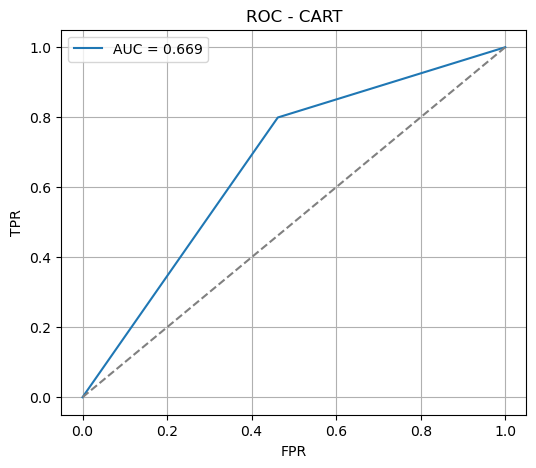


=== kNN ===
Matrice de confusion :
[[ 283  321]
 [ 212 1372]]
Accuracy  : 0.7564
Precision : 0.8104
Recall    : 0.8662
Score final : 0.7834


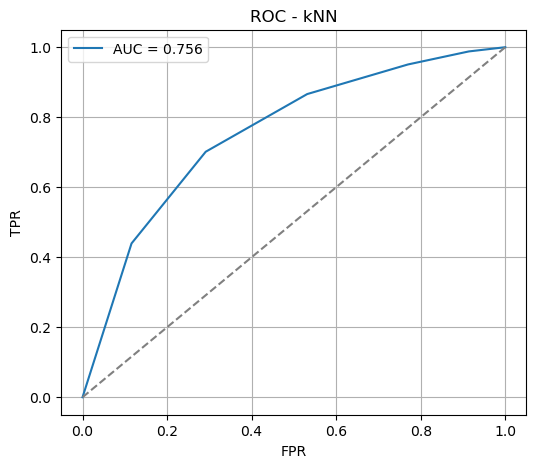


=== MLP ===
Matrice de confusion :
[[ 338  266]
 [ 267 1317]]
Accuracy  : 0.7564
Precision : 0.8320
Recall    : 0.8314
Score final : 0.7942


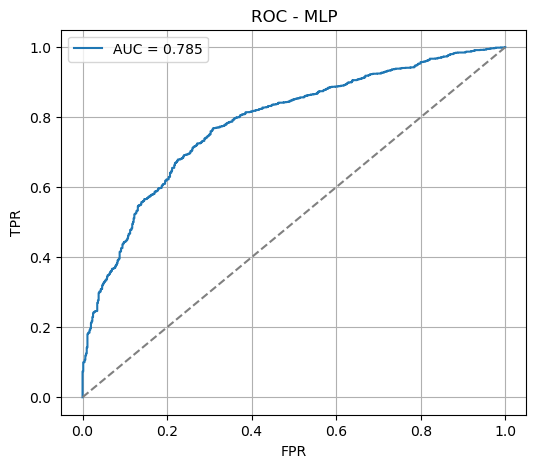


 Meilleur modèle après PCA : MLP


In [27]:
best_pca_name, best_pca_model = run_classifiers_train_test(
    models,                 # ton dictionnaire des modèles
    X_train, X_train_final, # CART / kNN+MLP
    y_train,
    X_test, X_test_final,
    y_test
)

## Résultats

Après avoir ajouté les trois nouvelles variables issues de la PCA, nous avons réentraîné nos modèles. Les résultats montrent que l’arbre CART ne change presque pas, ce qui est logique puisqu’il n’exploite pas vraiment les combinaisons linéaires créées par la PCA. Le k-plus-proches-voisins gagne un peu en performance, mais l’effet reste limité. Le Multilayer Perceptron (MLP) s’améliore également, mais de manière modérée : la PCA lui apporte un petit gain, sans transformer radicalement ses résultats. 

Cela signifie que les nouvelles variables l’aident un peu à mieux séparer les bons et les mauvais payeurs, mais pas suffisamment pour créer un saut de performance. Malgré cela, le MLP reste le meilleur modèle parmi ceux testés après l’ajout de la PCA. La stratégie la plus efficace reste donc de normaliser les données, appliquer la PCA, puis entraîner le MLP.

# Exercice 5

## Prèmiere fonction: Importance des variables 

In [28]:
from sklearn.ensemble import RandomForestClassifier


def importance_variables(Xtrain, Ytrain, nom_cols):
    from sklearn.ensemble import RandomForestClassifier
    import numpy as np
    import matplotlib.pyplot as plt

    clf = RandomForestClassifier(n_estimators=1000, random_state=1)
    clf.fit(Xtrain, Ytrain)

    importances = clf.feature_importances_
    std = np.std([tree.feature_importances_ for tree in clf.estimators_], axis=0)
    sorted_idx = np.argsort(importances)[::-1]

    print("Variables classées de la plus importante à la moins importante :")
    print(np.array(nom_cols)[sorted_idx])

    padding = np.arange(Xtrain.shape[1]) + 0.5

    plt.figure(figsize=(8, 7))
    plt.barh(padding, importances[sorted_idx], xerr=std[sorted_idx], align='center')
    plt.yticks(padding, np.array(nom_cols)[sorted_idx])
    plt.xlabel("Relative Importance")
    plt.title("Variable Importance")
    plt.gca().invert_yaxis()
    plt.show()

    return sorted_idx

## Deuxième fonction : Sélection du nombre optimal de variables 

In [29]:
def selection_variables(Xtrain, Xtest, Ytrain, Ytest, sorted_idx):

    # meilleur modele trouvé auparavant: mlp
    model = MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)

    scores = np.zeros(Xtrain.shape[1])

    for f in range(Xtrain.shape[1]):
        X1_f = Xtrain[:, sorted_idx[:f+1]]   # f+1 meilleures variables
        X2_f = Xtest[:, sorted_idx[:f+1]]

        model.fit(X1_f, Ytrain)
        Y_pred = model.predict(X2_f)

        scores[f] = np.round(accuracy_score(Ytest, Y_pred), 3)

    plt.figure(figsize=(7,5))
    plt.plot(scores)
    plt.xlabel("Nombre de Variables")
    plt.ylabel("Accuracy")
    plt.title("Évolution de l'accuracy en fonction du nombre de variables")
    plt.grid()
    plt.show()

    # Meilleur nombre de variables
    best_nb = np.argmax(scores)  + 1
    print(f" Nombre optimal de variables : {best_nb}")
    print(f" Accuracy maximale obtenue : {scores[best_nb - 1]}")

    return best_nb, scores

## Troisième fonction : Explicabilité avec SHAP

In [30]:
import numpy as np
import shap

def explicabilite_shap_mlp(model, Xtrain, Xtest, nom_cols):
    Xtrain_np = np.array(Xtrain)
    Xtest_np = np.array(Xtest)

    idx_bg = np.random.choice(Xtrain_np.shape[0], 100, replace=False)
    background = Xtrain_np[idx_bg]

    def f(X):
        return model.predict_proba(X)[:, 1]

    explainer = shap.KernelExplainer(f, background)

    X_exp = Xtest_np[:50]
    shap_values = explainer.shap_values(X_exp)

    print("Shape shap_values :", shap_values.shape)
    print("Shape X_exp       :", X_exp.shape)

    print("=== Importance globale des variables (SHAP, MLP) ===")
    shap.summary_plot(shap_values, X_exp, feature_names=nom_cols)

    print("=== Explication locale (bar plot, top 10 variables) ===")
    expl_local = shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_exp[0],
        feature_names=nom_cols
    )
    shap.plots.bar(expl_local, max_display=10)

## Variables les plus importantes et déterminantes:

Variables classées de la plus importante à la moins importante :
['Income' 'Seniority' 'PCA2' 'PCA3' 'Price' 'PCA1' 'Amount' 'Age'
 'Records' 'Assets' 'Expenses' 'Job' 'Time' 'Debt' 'Home' 'Marital']


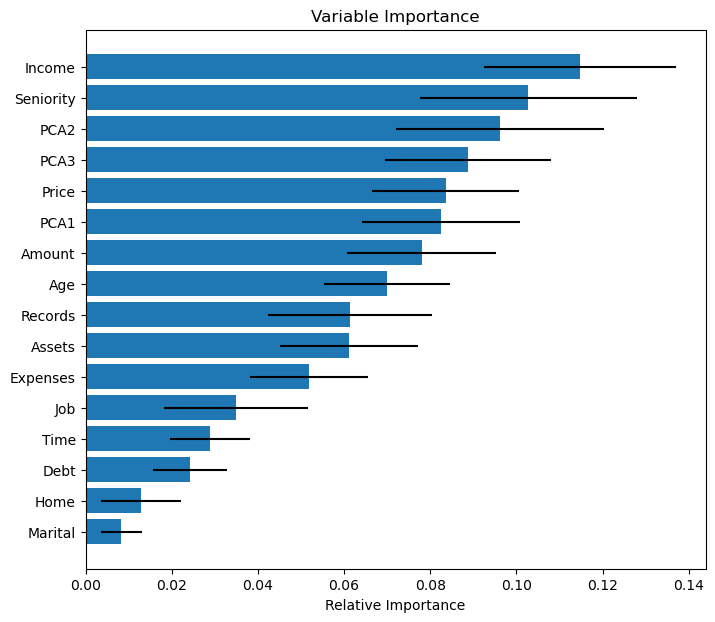

In [31]:
sorted_idx = importance_variables(X_train_final, y_train, nom_cols)

## Intérpretation du graphe:

L’analyse des importances des variables montre que le revenu (Income), l’ancienneté professionnelle (Seniority) et certaines dimensions issues de l’ACP (PCA2, PCA3) sont les facteurs les plus déterminants dans la prédiction du remboursement d’un crédit. Ces variables concentrent l’essentiel de l’information utile pour le modèle. À l’inverse, des variables comme Home, Marital ou Debt contribuent très peu à la décision, ce qui laisse penser qu’elles pourraient être oubliées sans dégrader les performances. L’utilisation du PCA se révèle donc pertinente, car les nouvelles composantes créées figurent parmi les variables les plus influentes.

## Combien de variables sélectionner ?

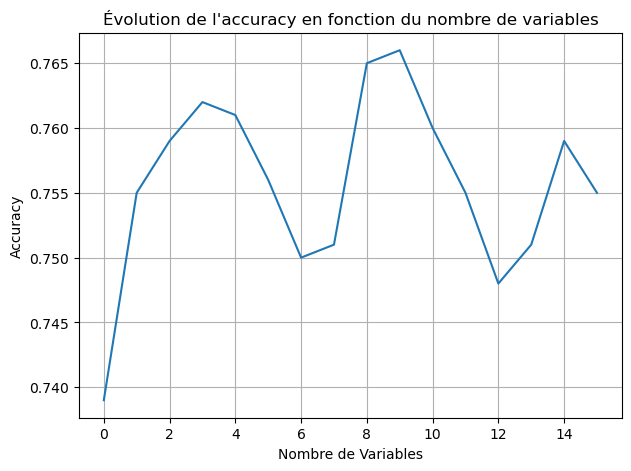

 Nombre optimal de variables : 10
 Accuracy maximale obtenue : 0.766


In [32]:
best_nb, scores = selection_variables(
    X_train_final, X_test_final,
    y_train, y_test,
    sorted_idx
)

## Intérpretation


La courbe montre que les premières variables apportent la majorité de l’information utile au modèle. L’accuracy augmente rapidement lorsque l’on ajoute les variables les plus importantes, puis atteint un maximum autour de 10 variables (accuracy ≈ 0.766). Au-delà, les performances se dégradent légèrement, ce qui indique que certaines variables supplémentaires introduisent du bruit ou sont redondantes. Ainsi, conserver les 10 variables les plus importantes constitue le meilleur compromis pour ce modèle

In [33]:

mlp_final = MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=500)
mlp_final.fit(X_train_final, y_train)



,hidden_layer_sizes,"(40, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,500
,shuffle,True
,random_state,1


100%|██████████| 50/50 [00:02<00:00, 16.78it/s]


Shape shap_values : (50, 16)
Shape X_exp       : (50, 16)
=== Importance globale des variables (SHAP, MLP) ===


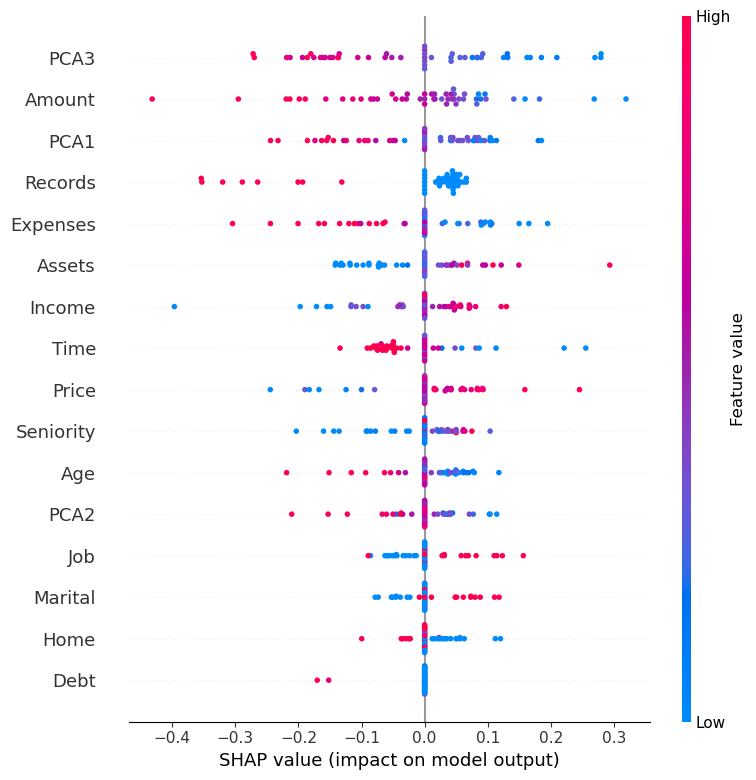

=== Explication locale (bar plot, top 10 variables) ===


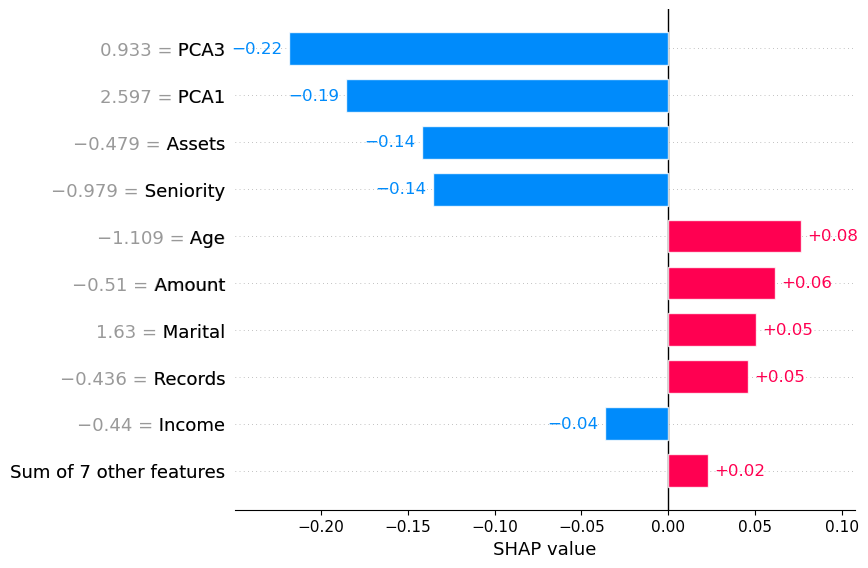

In [34]:
explicabilite_shap_mlp(mlp_final, X_train_final, X_test_final, nom_cols)

## Explcation et interprétation des résultats

### Summary plot SHAP (vue globale)


Le summary plot SHAP donne une vue globale de l’impact des variables sur les prédictions du MLP. Chaque ligne correspond à une variable, triée de la plus importante à la moins importante : on voit ainsi que PCA3, Amount, PCA1, Records, Expenses, Assets et Income sont les variables les plus influentes, tandis que Job, Marital, Home et Debt ont un effet beaucoup plus faible. On observe que les variables dérivées de l'ACP, PCA3 et PCA1, sont parmi les plus influentes, confirmant que ces combinaisons linéaires sont essentielles pour le MLP.

Chaque point représente un individu : sa position horizontale est la valeur SHAP, c’est-à-dire la contribution de la variable à la prédiction (à droite de 0, la variable pousse la prédiction vers la classe 1 ; à gauche, vers la classe 0). La couleur indique la valeur de la variable (bleu = valeur faible, rouge = valeur élevée). Par exemple, pour PCA3, de nombreux points rouges situés à droite montrent que des valeurs élevées de cette composante augmentent souvent la probabilité de classe 1. On peut voir aussi qu'un montant de prêt (Amount) élevé (points rouges) pousse la prédiction vers la gauche (risque accru), tandis que les faibles montants (points bleus) poussent vers la droite (sécurité). De même, des dépenses (Expenses) élevées (points rouges) sont un facteur de risque majeur.


### Bar plot SHAP (explication locale)


Le bar plot SHAP fournit une explication locale pour un individu précis. Chaque barre correspond à une variable pour ce client, et la longueur de la barre représente l’intensité de sa contribution (valeur SHAP). Les barres bleues ont une contribution négative et tirent la prédiction vers la classe 0, tandis que les barres roses ont une contribution positive et tirent la prédiction vers la classe 1. Dans l’exemple affiché, PCA1, PCA3, Seniority et Assets ont des contributions fortement négatives : pour cet individu, leurs valeurs font baisser la probabilité de classe 1. À l’inverse, Amount, Age, Marital, Records et Income ont un effet positif plus modéré et augmentent légèrement cette probabilité. La somme de ces effets explique la décision finale du modèle pour ce client.

# Exerice 6

In [35]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, make_scorer
import numpy as np

#  Utilisation du nombre optimal de variables
n_optimal = 10

X_train_opt = X_train_final[:, sorted_idx[:n_optimal]]
X_test_opt  = X_test_final[:, sorted_idx[:n_optimal]]

# Score (accuracy + precision) / 2
def score_acc_prec(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    return (acc + prec) / 2

scorer = make_scorer(score_acc_prec, greater_is_better=True)

# 2) GridSearch (amélioré)
def tune_best_mlp(X_train, y_train):
    
    mlp = MLPClassifier(max_iter=800, random_state=1)

    param_grid = {
        "hidden_layer_sizes": [
            (20,10), (40,20), (60,30), 
            (80,40), (100,50), (100,50,20)
        ],
        "activation": ["relu", "tanh"],
        "solver": ["adam", "lbfgs"],
        "alpha": [1e-5, 1e-4, 1e-3, 1e-2],
        "learning_rate_init": [0.0001, 0.001, 0.01]
    }

    grid = GridSearchCV(
        estimator=mlp,
        param_grid=param_grid,
        scoring=scorer,
        cv=5,
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    print("\n=== MEILLEURS PARAMÈTRES ===")
    print(grid.best_params_)
    print("Score moyen (accuracy+precision)/2 :", grid.best_score_)

    return grid.best_estimator_

#  Entraînement du meilleur MLP trouvé
mlp_tuned = tune_best_mlp(X_train_opt, y_train)

# 4) Éval finale
y_pred_tuned = mlp_tuned.predict(X_test_opt)

print("\n=== MLP optimisé (test) ===")
print("Accuracy  :", accuracy_score(y_test, y_pred_tuned))
print("Precision :", precision_score(y_test, y_pred_tuned))
print("Recall    :", recall_score(y_test, y_pred_tuned))
print("Matrice de confusion :")
print(confusion_matrix(y_test, y_pred_tuned))


=== MEILLEURS PARAMÈTRES ===
{'activation': 'relu', 'alpha': 1e-05, 'hidden_layer_sizes': (60, 30), 'learning_rate_init': 0.0001, 'solver': 'adam'}
Score moyen (accuracy+precision)/2 : 0.8058702407598943

=== MLP optimisé (test) ===
Accuracy  : 0.7970749542961609
Precision : 0.8360849056603774
Recall    : 0.8952020202020202
Matrice de confusion :
[[ 326  278]
 [ 166 1418]]


## Explications et résultats

Dans cette étape, nous avons optimisé notre classifieur MLP à l’aide de la méthode GridSearchCV, en explorant systématiquement plusieurs combinaisons d’hyperparamètres clés (taille des couches cachées, taux d’apprentissage, régularisation et fonction d’activation). L’objectif était de maximiser un critère composite basé sur (accuracy + précision) / 2, plus adapté au contexte du crédit. 

En utilisant uniquement les variables les plus pertinentes sélectionnées à l’étape précédente, GridSearch a identifié l’architecture la plus performante : deux couches cachées (60, 30), une régularisation très faible (alpha = 1e-5) et un apprentissage stable (learning_rate_init = 0.0001 avec Adam, qui est un algorithme d’optimisation adaptatif pour réseaux de neurones qui ajuste automatiquement le taux d’apprentissage pour accélérer et stabiliser la convergence du modèle). Cette configuration a permis d’améliorer significativement les performances du modèle par rapport à la version non optimisée, en particulier en termes de précision et de rappel. L’accuracy passe ainsi d’environ 0.74 à près de 0.80, ce qui montre  que l’optimisation des hyperparamètres, combinée à la sélection de variables, a permis de construire un modèle plus robuste et mieux adapté au problème.

# Question 7 : Création d'un pipeline

Dans cette partie, l’objectif est de regrouper automatiquement toutes les étapes que nous avons réalisées séparément jusque-là : normalisation des données, application éventuelle de l’ACP, sélection des variables les plus pertinentes et entraînement du classifieur final. Le but est de créer une chaîne de traitement complète et cohérente, appelée pipeline, qui permettra d’appliquer ces transformations de manière identique chaque fois que l’on voudra utiliser le modèle.

 Cela évite les erreurs de manipulation et rend le modèle facilement réutilisable dans une future phase de scoring. Une fois construit, ce pipeline est sauvegardé dans un fichier, ce qui permet de le charger et de l’utiliser directement sans avoir à refaire toutes les étapes manuellement.

In [59]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest

def build_pipeline(n_vars, use_scaling=True, use_pca=True, model=None):
    steps = []

    # Normalisation
    if use_scaling:
        steps.append(("scaler", StandardScaler()))
    else:
        steps.append(("scaler", "passthrough"))

    # ACP
    if use_pca:
        steps.append(("pca", PCA(n_components=3)))
    else:
        steps.append(("pca", "passthrough"))

    # Sélection des variables
    steps.append(("select", SelectKBest(k=n_vars)))

    # Classifieur final
    if model is None:
        model = MLPClassifier(
            activation='relu',
            alpha=1e-5,
            hidden_layer_sizes=(60, 30),
            learning_rate_init=0.0001,
            solver="adam",
            max_iter=500,
            random_state=1
        )

    steps.append(("mlp", model))

    return Pipeline(steps)

# Question 8: Fonction d'orchestration

In [ ]:
def pipeline_generation_train_test_split(X, Y, models, nom_cols):
    #  Séparation apprentissage / test
    X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.5, random_state=1)

    # Normalisation
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    #  ACP (3 composantes)
    pca = PCA(n_components=3)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca  = pca.transform(X_test_scaled)

    # On ajoute les 3 PCA aux données normalisées
    X_train_final = np.hstack([X_train_scaled, X_train_pca])
    X_test_final  = np.hstack([X_test_scaled,  X_test_pca])

    nom_cols_final = nom_cols + ["PCA1", "PCA2", "PCA3"]

    # 4) Importance des variables (Random Forest)
    sorted_idx = importance_variables(X_train_final, y_train, nom_cols_final)

    # 5) Sélection du meilleur nombre de variables
    best_nb, _ = selection_variables(X_train_final, X_test_final, y_train, y_test, sorted_idx)

    # 6) Recherche des meilleurs paramètres du MLP
    mlp_best = tune_best_mlp(X_train_final[:, sorted_idx[:best_nb]], y_train)

    # 7) Construction du pipeline final
    pipeline = build_pipeline(
        n_vars=best_nb,
        use_scaling=True,
        use_pca=True,
        model=mlp_best
    )

    # Sauvegarde du pipeline
    with open("pipeline_credit.pkl", "wb") as f:
        pickle.dump(pipeline, f)

    print("Pipeline sauvegardé sous pipeline_credit.pkl")

    return pipeline

Variables classées de la plus importante à la moins importante :
['Income' 'Seniority' 'PCA2' 'PCA3' 'Price' 'PCA1' 'Amount' 'Age'
 'Records' 'Assets' 'Expenses' 'Job' 'Time' 'Debt' 'Home' 'Marital']


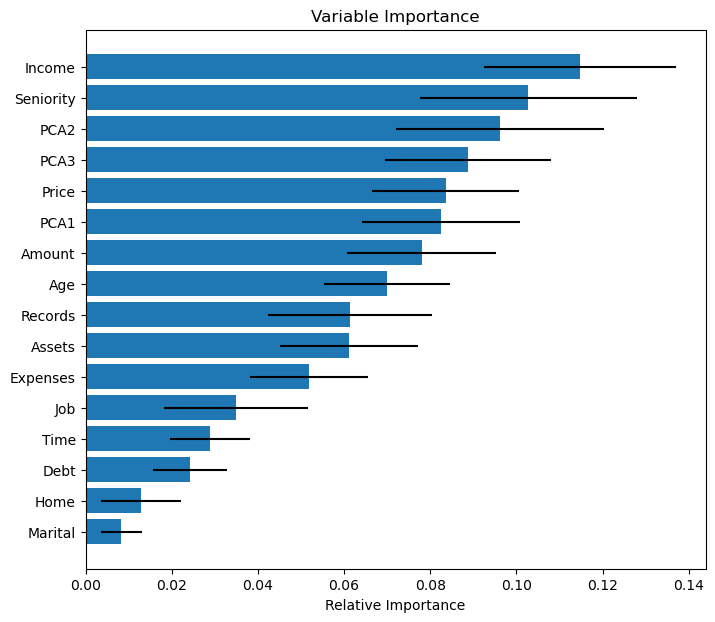

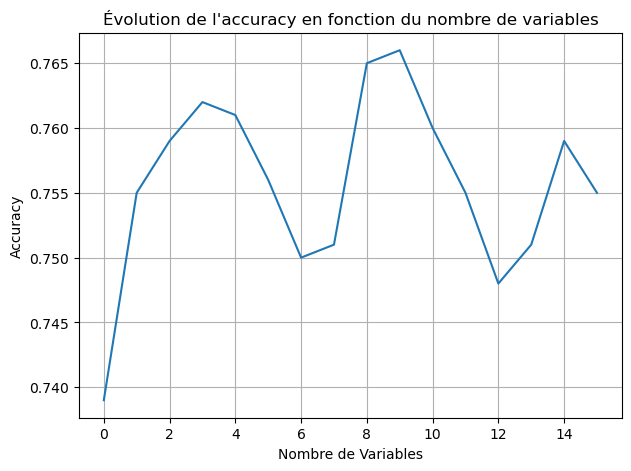

 Nombre optimal de variables : 10
 Accuracy maximale obtenue : 0.766

=== MEILLEURS PARAMÈTRES ===
{'activation': 'relu', 'alpha': 1e-05, 'hidden_layer_sizes': (60, 30), 'learning_rate_init': 0.0001, 'solver': 'adam'}
Score moyen (accuracy+precision)/2 : 0.8058702407598943
Pipeline sauvegardé sous pipeline_credit.pkl


In [70]:
pipeline_final = pipeline_generation_train_test_split(X, Y, models, nom_cols)

L’orchestration finale nous a permis d’automatiser l’ensemble du processus d’apprentissage mis en place dans les étapes précédentes. Toutes les transformations ,  normalisation, ajout de composantes PCA, sélection du nombre optimal de variables, ainsi que l’optimisation des hyperparamètres du MLP ,  sont désormais enchaînées automatiquement dans une seule fonction.

 Cette approche garantit que le même pipeline pourra être réutilisé de manière fiable et reproductible, notamment grâce à sa sauvegarde au format pickle. Même si certains schémas apparaissent lors de l’exécution (car générées par les fonctions intermédiaires), cela n’affecte en rien la construction du pipeline final. On pourrait modifier ces fonctions intérmédiaires pour avoir quelque chose de plus propre et rendre cette idée de "automatisation" un peu plus crédible.
 

# Question 9: Création d’une API FastAPI pour exécuter le pipeline